<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/241026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [442]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [443]:
df = pd.DataFrame(pd.read_csv('/content/Schizophrenia_Dataset(5)(1).csv')).drop(columns=['Tired', 'Race', 'Delay', 'Housing', 'Sex'])
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delusion,Dep_Mood,Focus,Hallucination,...,Passive,Pregnant,Psychomotor,Rumination,Sleep,Stress,Suspicious,Tension,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,1.170842,8.177884,8.305502,12.831823,...,4.385417,0.0,3.854579,5.041432,6.552082,5.915492,3.991749,6.371877,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,2.272548,11.162913,5.060206,38.979963,...,2.491285,NaN,5.821110,4.656790,5.558434,4.008265,NaN,2.238665,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,1.439095,5.887363,6.504229,11.296530,...,-999.000000,0.0,7.893102,7.290494,5.787561,7.177926,NaN,6.992499,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,1.380185,8.943851,6.994948,4.237368,...,-999.000000,0.0,3.812874,6.759339,6.787287,2.866815,NaN,4.018286,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,1.237976,6.741627,5.869212,0.863636,...,7.999254,NaN,5.119658,6.190019,7.748312,6.798220,5.103103,5.063542,0.705895,6.547707


In [444]:
df.dtypes

,0
Diagnosis,int64
Anhedonia,float64
Apathy,float64
Appetite,float64
Concentration,float64
Content,float64
Delusion,float64
Dep_Mood,float64
Focus,float64
Hallucination,float64


In [445]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
#for impoertances
from sklearn.ensemble import RandomForestClassifier

      count
4999      1
0         1
3         1
4         1
4974      1
...     ...
20        1
19        1
17        1
12        1
10        1

[2500 rows x 1 columns]


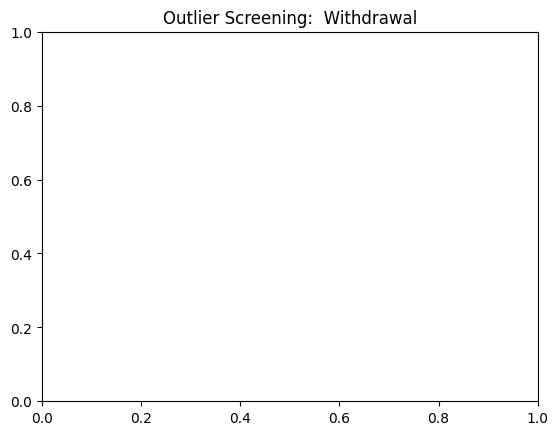

In [446]:
#initial, loose grouping of numerical and categorical based on number of unique values
numcols_strings = [col for col in df.columns if df[col].nunique() > 6]
numdf = df[numcols_strings]
#print(numdf.dtypes)

def outlier_frequency_func(numdf, p1 = 25, p2 = 75):
  ### docstring here ###
  for col in numdf:
    plt.title(f'Outlier Screening:  {col}')
    #plt.boxplot(df[col])
    #plt.show()

    col_outliers = []

    for i, val in enumerate(numdf[col]):
      if (val < np.percentile(numdf[col], 25)) or (val > np.percentile(numdf[col], 75)):
        col_outliers.append(i)

  #values count for each shows how many times each row has an outlier overall
  outlier_row_count = pd.Series(col_outliers).value_counts()
  return outlier_row_count

#mask takes OUT those that don't fit condition, replacing with nan --> use dropna
orc = pd.DataFrame(outlier_frequency_func(numdf))
print(orc)
outlier_present_mask = orc.mask(orc.values <= 2).dropna()
#it appears there are no rows with 2+ outliers... seems unlikely
#CHECK
max(orc)    #is 1... unrealistic, mention to John, len 2500: half have a single

orc.index.nunique()

df_outlier = df.iloc[orc.index]

In [447]:
y = df['Diagnosis']
X = df.drop(columns = ['Diagnosis'])

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=23)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=23)

num = df[[col for col in X.columns if df[col].nunique() > 6]].columns
cat = df[[col for col in X.columns if df[col].nunique() <= 6]].columns

pcat = Pipeline(steps = [('imp_cat', SimpleImputer(strategy='most_frequent')),
                         ('encoder', OneHotEncoder(sparse_output=False))])
pnum = Pipeline(steps = [('num_imp', SimpleImputer()),
                         ('scaler', StandardScaler())])
prep = ColumnTransformer(transformers = [('num_prep', pnum,num ),
                                         ('cat_prep', pcat, cat)]).set_output(transform='pandas')
final_pipe = Pipeline(steps = [('prep_pipe', prep)]).set_output(transform = 'pandas')

final_pipe.fit(X_train, y_train)

#print(final_pipe[-1])

colnames = final_pipe[-1].get_feature_names_out()

final_pipe.transform(X_test)
final_pipe.transform(X_val)

X_val.shape


(500, 21)

In [448]:
X_train_prep = final_pipe.fit_transform(X_train)
X_test_prep = final_pipe.transform(X_test)
X_val_prep = final_pipe.transform(X_val)

In [449]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score

In [450]:
X_train_prep.isnull().sum()

,0
num_prep__Anhedonia,0
num_prep__Apathy,0
num_prep__Appetite,0
num_prep__Concentration,0
num_prep__Content,0
num_prep__Delusion,0
num_prep__Dep_Mood,0
num_prep__Focus,0
num_prep__Hallucination,0
num_prep__Intrusive_Thoughts,0


In [451]:
pd.DataFrame(X_test_prep).dtypes

,0
num_prep__Anhedonia,float64
num_prep__Apathy,float64
num_prep__Appetite,float64
num_prep__Concentration,float64
num_prep__Content,float64
num_prep__Delusion,float64
num_prep__Dep_Mood,float64
num_prep__Focus,float64
num_prep__Hallucination,float64
num_prep__Intrusive_Thoughts,float64


In [452]:
X_train_tensor = torch.tensor(X_train_prep.values, dtype = torch.float32)
X_test_tensor = torch.tensor(X_test_prep.values, dtype = torch.float32)
X_val_tensor = torch.tensor(X_val_prep.values, dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype = torch.long)
y_test_tensor = torch.tensor(y_test.values, dtype = torch.long)
y_val_tensor = torch.tensor(y_val.values, dtype = torch.long)

In [453]:
print(X_train_tensor)

tensor([[ 0.1019,  0.2803,  0.4899,  ...,  1.0000,  0.0000,  1.0000],
        [-0.3134, -1.1881,  1.7121,  ...,  1.0000,  0.0000,  1.0000],
        [-1.6367, -0.0817,  0.3305,  ...,  1.0000,  1.0000,  0.0000],
        ...,
        [ 0.0169, -1.0762,  0.8277,  ...,  1.0000,  1.0000,  0.0000],
        [ 0.8939, -0.5397,  0.6207,  ...,  1.0000,  1.0000,  0.0000],
        [ 0.2146,  0.2576, -1.1336,  ...,  1.0000,  1.0000,  0.0000]])


In [527]:

class VanillaNeuralNetwork(nn.Module):
  def __init__(self):
    super(VanillaNeuralNetwork, self).__init__()
    self.fc1 =  nn.Linear(22, 100)
    self.relu1 = nn.ReLU()
    self.fc2 = nn.Linear(100, 25)
    self.relu2 = nn.ReLU()
    self.fc3 = nn.Linear(25, 2)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    #x = torch.tensor(x)
    x = self.fc1(x)
    x= self.relu1(x)
    x = self.fc2(x)
    x = self.relu2(x)
    x = self.fc3(x)
    x = self.sigmoid(x)
    return x

model = VanillaNeuralNetwork()

loss_list = []
val_loss_list = []

loss_func = torch.nn.CrossEntropyLoss()
opt = optim.Adam(model.parameters(), lr= 0.001)
num_epochs = 100

  #batch should be tensors

for epoch in range(num_epochs):
  opt.zero_grad()
  preds = model(X_test_tensor)
  loss = loss_func(preds, y_test_tensor)
  loss.backward()
  opt.step()
  loss_list.append(loss.item())

  val_hat = model(X_val_tensor)
  val_loss_list.append(loss_func(val_hat, y_val_tensor))#.detach().numpy())

print(loss_list)
print(val_loss_list)

  #return loss_list, val_loss_list

[0.6915410161018372, 0.6877971291542053, 0.6840766072273254, 0.680359959602356, 0.6766101717948914, 0.6728323101997375, 0.6690157651901245, 0.6651222705841064, 0.6611526608467102, 0.6570838689804077, 0.6529068350791931, 0.6486290097236633, 0.6442148089408875, 0.6396562457084656, 0.6349578499794006, 0.6301242113113403, 0.6251417398452759, 0.6200085282325745, 0.6147173047065735, 0.6092740297317505, 0.6036924719810486, 0.597961962223053, 0.5920955538749695, 0.5861009955406189, 0.5799975395202637, 0.573815107345581, 0.5675433874130249, 0.5611991286277771, 0.5548064708709717, 0.5483888983726501, 0.5419747829437256, 0.5355770587921143, 0.5292298793792725, 0.5229554176330566, 0.5167744755744934, 0.5107073187828064, 0.5047668814659119, 0.49896591901779175, 0.4933222234249115, 0.4878511130809784, 0.4825630187988281, 0.477466881275177, 0.4725709855556488, 0.46788012981414795, 0.4633945822715759, 0.45911505818367004, 0.4550408124923706, 0.45116785168647766, 0.44749099016189575, 0.4440055191516876

In [535]:
len(val_loss_list)

vl2 = []

for num in range(0, 99):
  vl2.append(val_loss_list[num].tolist())

vl2

[0.6876633167266846,
 0.6840323805809021,
 0.6804177761077881,
 0.6767793893814087,
 0.6730930209159851,
 0.6693521738052368,
 0.6655457615852356,
 0.6616683006286621,
 0.657697319984436,
 0.6536131501197815,
 0.6493985056877136,
 0.6450578570365906,
 0.6405952572822571,
 0.6359873414039612,
 0.6312125325202942,
 0.6262778639793396,
 0.6211850643157959,
 0.6159310340881348,
 0.6105299592018127,
 0.6049845218658447,
 0.5992932915687561,
 0.5934635400772095,
 0.5875108242034912,
 0.5814492702484131,
 0.5752824544906616,
 0.5690339207649231,
 0.5627171397209167,
 0.5563378930091858,
 0.5499364137649536,
 0.5435407757759094,
 0.5371580123901367,
 0.530806839466095,
 0.5245174765586853,
 0.5183187127113342,
 0.5122249126434326,
 0.5062674283981323,
 0.5004569292068481,
 0.49481064081192017,
 0.48934757709503174,
 0.48408541083335876,
 0.479035884141922,
 0.47420161962509155,
 0.4695916473865509,
 0.4652095139026642,
 0.4610535502433777,
 0.45712578296661377,
 0.45342305302619934,
 0.4499391

<Axes: >

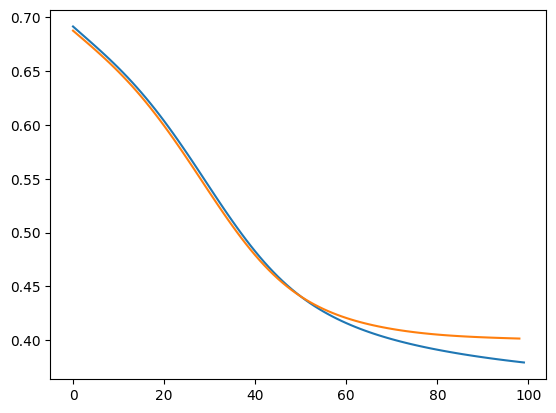

In [536]:
pd.Series(loss_list).plot()
pd.Series(vl2).plot()